# TP — Comptage d'occurrences de mots (WordCount)

**Auteur :** Najib Mounsif

**Environnement :** Ubuntu 24.04 · Python 3.12 · OpenJDK 21 · Apache Hadoop 3.5.0 (mode local) · PySpark 4

## Problème
On veut compter le nombre d'occurrences de chaque mot d'un fichier texte, et comparer plusieurs façons de le faire quand la taille du fichier augmente :
1. **Python séquentiel simple** : un dictionnaire et une boucle ;
2. **Pseudo-MapReduce en Python** : les étapes map → shuffle → reduce simulées localement ;
3. **Hadoop MapReduce** : le vrai job `wordcount` fourni avec Hadoop ;
4. **PySpark** : le même comptage avec Apache Spark (RDD `flatMap` → `map` → `reduceByKey`).

Les méthodes sont d'abord testées sur le petit fichier du rapport, puis comparées sur **des fichiers de tailles croissantes** : un fichier de N lignes (un mot par ligne, avec répétitions), puis des fichiers de m×N lignes obtenus en dupliquant ces N lignes m fois.

**Plan**
0. Données d'entrée
1. Version 1 : Python simple
2. Version 2 : Pseudo-MapReduce
3. Version 3 : Hadoop MapReduce
4. Version 4 : PySpark
5. Fichiers de tailles croissantes (N, m×N)
6. Vérification avec une référence indépendante
7. Mesures de performance
8. Analyse
9. Conclusion

## 0. Données d'entrée
Fichier `mots.txt` du rapport (85 mots).

In [1]:
%%writefile mots.txt
montagne soleil arbre chien maison livre route chat
ciel chien mer montagne chat soleil chat chien
ciel jardin chat chat livre arbre livre maison
voiture fleur chat arbre arbre fleur chien chat
chat fleur mer chat chien lune chat chat
arbre fleur chat fleur chien chat chat maison
montagne lune chat montagne chat ciel fleur chat
montagne fleur chat soleil maison route arbre soleil
route maison chien mer livre chien chien lune
oiseau chat soleil chat ciel chat chat chien
chien arbre chat chat oiseau

Overwriting mots.txt


In [2]:
import os, time, glob, shutil, subprocess, statistics, random
from collections import defaultdict, Counter

with open('mots.txt', encoding='utf-8') as f:
    print(f"{len(f.read().split())} mots dans le fichier")

85 mots dans le fichier


## 1. Version 1 : Python simple
Lecture du fichier et comptage avec un dictionnaire.

In [3]:
def compter_occurrences(fichier):
    with open(fichier, 'r', encoding='utf-8') as f:
        mots = f.read().split()
    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

res_v1 = compter_occurrences('mots.txt')
for mot, nb in sorted(res_v1.items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {nb}")

chat : 24
chien : 11
arbre : 7
fleur : 7
montagne : 5
soleil : 5
maison : 5
livre : 4
ciel : 4
route : 3
mer : 3
lune : 3
oiseau : 2
jardin : 1
voiture : 1


## 2. Version 2 : Pseudo-MapReduce Python
- **map** : chaque ligne → liste de paires `(mot, 1)`
- **shuffle** : regroupement des valeurs par clé
- **reduce** : somme des valeurs pour chaque clé

In [4]:
def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced

def mapreduce_local(fichier):
    mapped = []
    with open(fichier, 'r', encoding='utf-8') as f:
        for ligne in f:
            mapped.extend(mapper(ligne))
    return reducer(shuffle(mapped))

# Détail des étapes sur le petit fichier
with open('mots.txt', encoding='utf-8') as f:
    mapped = [p for ligne in f for p in mapper(ligne)]
grouped = shuffle(mapped)
print('Sortie map (extrait)    :', mapped[:5])
print('Sortie shuffle (extrait):', {k: grouped[k] for k in list(grouped)[:3]})
print()
res_v2 = mapreduce_local('mots.txt')
for mot, nb in sorted(res_v2.items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {nb}")

Sortie map (extrait)    : [('montagne', 1), ('soleil', 1), ('arbre', 1), ('chien', 1), ('maison', 1)]
Sortie shuffle (extrait): {'montagne': [1, 1, 1, 1, 1], 'soleil': [1, 1, 1, 1, 1], 'arbre': [1, 1, 1, 1, 1, 1, 1]}

chat : 24
chien : 11
arbre : 7
fleur : 7
montagne : 5
soleil : 5
maison : 5
livre : 4
ciel : 4
route : 3
mer : 3
lune : 3
oiseau : 2
jardin : 1
voiture : 1


## 3. Version 3 : Hadoop MapReduce

### 3.1 Installation (terminal)
Hadoop est utilisé en **mode local** (*standalone*) : il suffit de Java et de l'archive Hadoop, sans configuration XML, sans SSH ni démarrage de HDFS/YARN.
```bash
sudo apt install openjdk-21-jdk
wget https://dlcdn.apache.org/hadoop/common/stable/hadoop-3.5.0.tar.gz
tar -xzf hadoop-3.5.0.tar.gz && mv hadoop-3.5.0 ~/hadoop
~/hadoop/bin/hadoop version
```

### 3.2 Lancement depuis le notebook
La fonction `hadoop_wordcount` lance le job `wordcount` du fichier `hadoop-mapreduce-examples-*.jar`, lit le résultat `part-r-00000` et chronomètre le job.
- En **mode local**, Hadoop lit et écrit directement sur le disque (pas de copie : le temps de copie vaut 0).
- Si un cluster **pseudo-distribué** (HDFS + YARN) est configuré et démarré, la fonction copie d'abord le fichier sur HDFS et chronomètre cette copie à part.
- Si Hadoop est absent, la fonction renvoie `None`.

In [5]:
HADOOP_HOME = os.environ.get('HADOOP_HOME', os.path.expanduser('~/hadoop'))
os.environ['HADOOP_HOME'] = HADOOP_HOME
if 'JAVA_HOME' not in os.environ and shutil.which('java'):
    java = os.path.realpath(shutil.which('java'))
    os.environ['JAVA_HOME'] = os.path.dirname(os.path.dirname(java))

HADOOP = shutil.which('hadoop') or os.path.join(HADOOP_HOME, 'bin', 'hadoop')
HDFS   = shutil.which('hdfs')   or os.path.join(HADOOP_HOME, 'bin', 'hdfs')
jars   = glob.glob(os.path.join(HADOOP_HOME, 'share/hadoop/mapreduce/hadoop-mapreduce-examples-*.jar'))
JAR    = jars[0] if jars else None
USER   = os.environ.get('USER', 'najib')

def sh(*cmd):
    return subprocess.run(list(cmd), capture_output=True, text=True)

HADOOP_DISPO = os.path.exists(HADOOP) and JAR is not None
def hdfs_actif():
    """Vrai seulement si Hadoop est configuré avec HDFS (hdfs://...) et que HDFS répond."""
    if not HADOOP_DISPO:
        return False
    fs = sh(HDFS, 'getconf', '-confKey', 'fs.defaultFS').stdout.strip()
    return fs.startswith('hdfs://') and sh(HDFS, 'dfs', '-ls', '/').returncode == 0

HDFS_ACTIF = hdfs_actif()
mode = 'pseudo-distribué (HDFS + YARN)' if HDFS_ACTIF else ('local (sans HDFS)' if HADOOP_DISPO else '—')
print(f"Hadoop installé : {HADOOP_DISPO} | mode : {mode} | jar : {JAR}")

Hadoop installé : True | mode : local (sans HDFS) | jar : /home/najib/hadoop/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.5.0.jar


In [6]:
def lire_sortie_hadoop(texte):
    """Convertit les lignes 'mot\tcompte' de part-r-* en dictionnaire."""
    res = {}
    for ligne in texte.splitlines():
        if '\t' in ligne:
            mot, nb = ligne.split('\t')
            res[mot] = int(nb)
    return res

def hadoop_wordcount(fichier, nom):
    """Renvoie (résultat, temps_copie_s, temps_job_s), ou (None, nan, nan)."""
    nan = float('nan')
    if not HADOOP_DISPO:
        return None, nan, nan

    if HDFS_ACTIF:
        entree = f'/user/{USER}/wordcount/{nom}/input'
        sortie = f'/user/{USER}/wordcount/{nom}/output'
        sh(HDFS, 'dfs', '-rm', '-r', '-f', f'/user/{USER}/wordcount/{nom}')
        t0 = time.perf_counter()
        sh(HDFS, 'dfs', '-mkdir', '-p', entree)
        sh(HDFS, 'dfs', '-put', '-f', fichier, entree + '/')
        t_copie = time.perf_counter() - t0
    else:  # mode local : pas de HDFS
        entree = 'file://' + os.path.abspath(fichier)
        dossier = os.path.abspath(f'hadoop_out/{nom}')
        shutil.rmtree(dossier, ignore_errors=True)
        sortie = 'file://' + dossier
        t_copie = 0.0

    t0 = time.perf_counter()
    job = sh(HADOOP, 'jar', JAR, 'wordcount', entree, sortie)
    t_job = time.perf_counter() - t0
    if job.returncode != 0:
        print('Le job Hadoop a échoué :\n', job.stderr[-600:])
        return None, t_copie, nan

    if HDFS_ACTIF:
        texte = sh(HDFS, 'dfs', '-cat', sortie + '/part-r-*').stdout
    else:
        texte = ''.join(open(p, encoding='utf-8').read() for p in glob.glob(dossier + '/part-r-*'))
    return lire_sortie_hadoop(texte), t_copie, t_job

res_v3, t_copie, t_job = hadoop_wordcount('mots.txt', 'rapport')
if res_v3 is not None:
    for mot, nb in sorted(res_v3.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")
    print(f"\nJob Hadoop : {t_job:.2f} s (copie HDFS : {t_copie:.2f} s)")
else:
    print("Hadoop n'est pas disponible : vérifier que ~/hadoop/bin/hadoop existe et que Java est installé.")

chat : 24
chien : 11
arbre : 7
fleur : 7
maison : 5
montagne : 5
soleil : 5
ciel : 4
livre : 4
lune : 3
mer : 3
route : 3
oiseau : 2
jardin : 1
voiture : 1

Job Hadoop : 2.14 s (copie HDFS : 0.00 s)


## 4. Version 4 : PySpark

Spark reprend le modèle MapReduce, mais garde les données intermédiaires **en mémoire** au lieu de les écrire sur disque entre chaque étape. Le comptage s'écrit en trois transformations sur un **RDD** (ensemble de données distribué), qui correspondent directement aux étapes de la version 2 :

| Étape | Pseudo-MapReduce (V2) | PySpark |
|---|---|---|
| découpage en mots + map | `mapper(ligne)` → `(mot, 1)` | `flatMap(split)` puis `map(lambda mot: (mot, 1))` |
| shuffle + reduce | `shuffle()` puis `reducer()` | `reduceByKey(lambda a, b: a + b)` |

Les transformations sont **paresseuses** : rien n'est calculé tant qu'on ne demande pas un résultat (ici `collect()`).

**Installation** (dans le venv du TP) : `pip install pyspark`. Spark tourne ici en mode `local[*]` : un seul ordinateur, un thread par cœur du processeur.

In [7]:
import sys
os.environ.setdefault('PYSPARK_PYTHON', sys.executable)

try:
    from pyspark.sql import SparkSession
    t0 = time.perf_counter()
    spark = (SparkSession.builder
             .master('local[*]')
             .appName('wordcount')
             .config('spark.ui.showConsoleProgress', 'false')
             .getOrCreate())
    t_demarrage_spark = time.perf_counter() - t0
    spark.sparkContext.setLogLevel('ERROR')
    sc = spark.sparkContext
    SPARK_DISPO = True
    print(f"Spark {spark.version} démarré en {t_demarrage_spark:.1f} s | {sc.defaultParallelism} threads")
except Exception as e:
    SPARK_DISPO = False
    print("PySpark n'est pas disponible :", e)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/13 16:32:23 WARN Utils: Your hostname, Najib, resolves to a loopback address: 127.0.1.1; using 10.245.85.252 instead (on interface wlo1)
26/10/13 16:32:23 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/najib/tp-wordcount/venv/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/13 16:32:24 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 démarré en 4.3 s | 8 threads


In [8]:
def spark_wordcount(fichier):
    if not SPARK_DISPO:
        return None
    lignes = sc.textFile('file://' + os.path.abspath(fichier))
    comptes = (lignes.flatMap(lambda ligne: ligne.split())   # une ligne -> ses mots
                     .map(lambda mot: (mot, 1))              # map : (mot, 1)
                     .reduceByKey(lambda a, b: a + b))       # shuffle + reduce
    return dict(comptes.collect())

res_v4 = spark_wordcount('mots.txt')
if res_v4 is not None:
    for mot, nb in sorted(res_v4.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")

chat : 24
chien : 11
arbre : 7
fleur : 7
soleil : 5
maison : 5
montagne : 5
livre : 4
ciel : 4
route : 3
lune : 3
mer : 3
oiseau : 2
jardin : 1
voiture : 1


Le plan d'exécution construit par Spark montre les deux étapes séparées par un **shuffle** (`ShuffledRDD`), exactement comme entre le map et le reduce de MapReduce :

In [9]:
if SPARK_DISPO:
    plan = (sc.textFile('file://' + os.path.abspath('mots.txt'))
              .flatMap(lambda ligne: ligne.split())
              .map(lambda mot: (mot, 1))
              .reduceByKey(lambda a, b: a + b))
    print(plan.toDebugString().decode())

(2) PythonRDD[13] at RDD at PythonRDD.scala:59 []
 |  MapPartitionsRDD[12] at mapPartitions at PythonRDD.scala:197 []
 |  ShuffledRDD[11] at partitionBy at DirectMethodHandleAccessor.java:103 []
 +-(2) PairwiseRDD[10] at reduceByKey at /tmp/ipykernel_24171/3211364815.py:5 []
    |  PythonRDD[9] at reduceByKey at /tmp/ipykernel_24171/3211364815.py:5 []
    |  file:///home/najib/tp-wordcount/mots.txt MapPartitionsRDD[8] at textFile at DirectMethodHandleAccessor.java:103 []
    |  file:///home/najib/tp-wordcount/mots.txt HadoopRDD[7] at textFile at DirectMethodHandleAccessor.java:103 []


## 5. Fichiers de tailles croissantes
Comme demandé dans l'énoncé :
- on génère un **fichier de N lignes, chaque ligne contenant un mot** (avec répétitions), tiré du même vocabulaire et avec les mêmes fréquences relatives que `mots.txt` ;
- on génère des fichiers plus gros de **m×N lignes** en dupliquant ces N lignes m fois ;
- on fait varier m pour obtenir des fichiers de plus en plus gros.

Avec N = 10 000 et m ∈ {1, 10, 100, 500}, on va de 10 000 à 5 millions de lignes. Les valeurs de m restent modérées à cause du temps d'exécution (la version pseudo-MapReduce garde toutes les paires en mémoire).

In [10]:
N = 10_000                  # lignes du fichier de base
MOTS_PAR_LIGNE = 1         # un mot par ligne (énoncé)
M_VALEURS = [1, 10, 100, 500]  # facteurs de duplication

vocab, poids = zip(*Counter(open('mots.txt', encoding='utf-8').read().split()).items())

def creer_fichier_base(chemin, n_lignes, seed=0):
    rng = random.Random(seed)
    with open(chemin, 'w', encoding='utf-8') as f:
        for _ in range(n_lignes):
            f.write(' '.join(rng.choices(vocab, weights=poids, k=MOTS_PAR_LIGNE)) + '\n')

def dupliquer(source, m, chemin):
    with open(source, encoding='utf-8') as f:
        bloc = f.read()
    with open(chemin, 'w', encoding='utf-8') as f:
        f.write(bloc * m)

os.makedirs('donnees', exist_ok=True)
creer_fichier_base('donnees/base.txt', N)

fichiers = {}
for m in M_VALEURS:
    chemin = f'donnees/mots_{m}xN.txt'
    dupliquer('donnees/base.txt', m, chemin)
    fichiers[m] = chemin
    print(f"m = {m:>3} | {m*N:>9,} lignes | {os.path.getsize(chemin)/1e6:6.2f} Mo")

with open('donnees/base.txt', encoding='utf-8') as f:
    print('\nDébut du fichier de base :', [next(f).strip() for _ in range(8)])

m =   1 |    10,000 lignes |   0.06 Mo
m =  10 |   100,000 lignes |   0.59 Mo
m = 100 | 1,000,000 lignes |   5.91 Mo
m = 500 | 5,000,000 lignes |  29.55 Mo

Début du fichier de base : ['jardin', 'ciel', 'livre', 'chien', 'chat', 'livre', 'ciel', 'chien']


## 6. Vérification avec une référence indépendante
`collections.Counter` sert de référence : il ne partage aucun code avec nos méthodes. On vérifie :
1. que les quatre méthodes donnent exactement le résultat de `Counter` (petit fichier et fichier de base) ;
2. que la duplication est cohérente : **comptage(m×N) = m × comptage(N)** pour chaque m.

In [11]:
def reference(fichier):
    with open(fichier, encoding='utf-8') as f:
        return dict(Counter(f.read().split()))

def statut(resultat, ref):
    if resultat is None:
        return 'non testé'
    assert resultat == ref
    return 'OK'

for fichier in ['mots.txt', 'donnees/base.txt']:
    ref = reference(fichier)
    assert compter_occurrences(fichier) == ref, f'V1 incorrecte sur {fichier}'
    assert mapreduce_local(fichier) == ref, f'V2 incorrecte sur {fichier}'
    r3, _, _ = hadoop_wordcount(fichier, 'verif_' + os.path.basename(fichier).split('.')[0])
    r4 = spark_wordcount(fichier)
    print(f"{fichier:<18} V1 OK | V2 OK | Hadoop {statut(r3, ref)} | PySpark {statut(r4, ref)}")

ref_base = reference('donnees/base.txt')
for m, chemin in fichiers.items():
    attendu = {mot: m * nb for mot, nb in ref_base.items()}
    assert compter_occurrences(chemin) == attendu, f'Incohérence pour m={m}'
print('\ncomptage(m×N) = m × comptage(N) vérifié pour m =', M_VALEURS)

mots.txt           V1 OK | V2 OK | Hadoop OK | PySpark OK
donnees/base.txt   V1 OK | V2 OK | Hadoop OK | PySpark OK

comptage(m×N) = m × comptage(N) vérifié pour m = [1, 10, 100, 500]


## 7. Mesures de performance
Chaque méthode est lancée sur **le même fichier**, pour chaque taille.
- **Python et PySpark** : médiane de 3 exécutions avec `time.perf_counter()`. Pour PySpark, la session Spark est déjà démarrée : son temps de démarrage (mesuré plus haut) n'est pas compté.
- **Hadoop** : une exécution de bout en bout, qui inclut le démarrage de Java à chaque job ; le temps de copie sur HDFS est noté à part (0 en mode local).

In [12]:
def mediane_temps(fonction, fichier, repetitions=3):
    temps = []
    for _ in range(repetitions):
        t0 = time.perf_counter()
        resultat = fonction(fichier)
        temps.append(time.perf_counter() - t0)
    return statistics.median(temps), resultat

mesures = []
for m, chemin in fichiers.items():
    t1, r1 = mediane_temps(compter_occurrences, chemin)
    t2, r2 = mediane_temps(mapreduce_local, chemin)
    r3, tc, t3 = hadoop_wordcount(chemin, f'm{m}')
    t4, r4 = mediane_temps(spark_wordcount, chemin) if SPARK_DISPO else (float('nan'), None)
    assert r1 == r2 and (r3 is None or r3 == r1) and (r4 is None or r4 == r1)
    mesures.append({'m': m, 'lignes': m * N, 'Mo': os.path.getsize(chemin) / 1e6,
                    'Python simple (s)': t1, 'Pseudo-MapReduce (s)': t2,
                    'Hadoop job (s)': t3, 'PySpark (s)': t4, 'Copie HDFS (s)': tc})
    print(f'm = {m:>3} mesuré')

m =   1 mesuré
m =  10 mesuré
m = 100 mesuré
m = 500 mesuré


In [13]:
import pandas as pd

df = pd.DataFrame(mesures)
df['Surcoût pseudo-MR (×)'] = df['Pseudo-MapReduce (s)'] / df['Python simple (s)']
df['Hadoop / Python (×)'] = df['Hadoop job (s)'] / df['Python simple (s)']
df['PySpark / Python (×)'] = df['PySpark (s)'] / df['Python simple (s)']
df.style.format({'Mo': '{:.2f}', 'lignes': '{:,}',
                 'Python simple (s)': '{:.4f}', 'Pseudo-MapReduce (s)': '{:.4f}',
                 'Hadoop job (s)': '{:.2f}', 'PySpark (s)': '{:.3f}', 'Copie HDFS (s)': '{:.2f}',
                 'Surcoût pseudo-MR (×)': '{:.2f}', 'Hadoop / Python (×)': '{:.0f}',
                 'PySpark / Python (×)': '{:.1f}'}, na_rep='—')

,m,lignes,Mo,Python simple (s),Pseudo-MapReduce (s),Hadoop job (s),PySpark (s),Copie HDFS (s),Surcoût pseudo-MR (×),Hadoop / Python (×),PySpark / Python (×)
0,1,"10,000",0.06,0.0016,0.0034,2.03,0.192,0.00,2.07,1235,116.4
1,10,"100,000",0.59,0.0121,0.0346,2.15,0.191,0.00,2.86,178,15.8
2,100,"1,000,000",5.91,0.1212,0.3668,2.04,0.674,0.00,3.03,17,5.6
3,500,"5,000,000",29.55,0.6401,1.8828,5.20,4.172,0.00,2.94,8,6.5


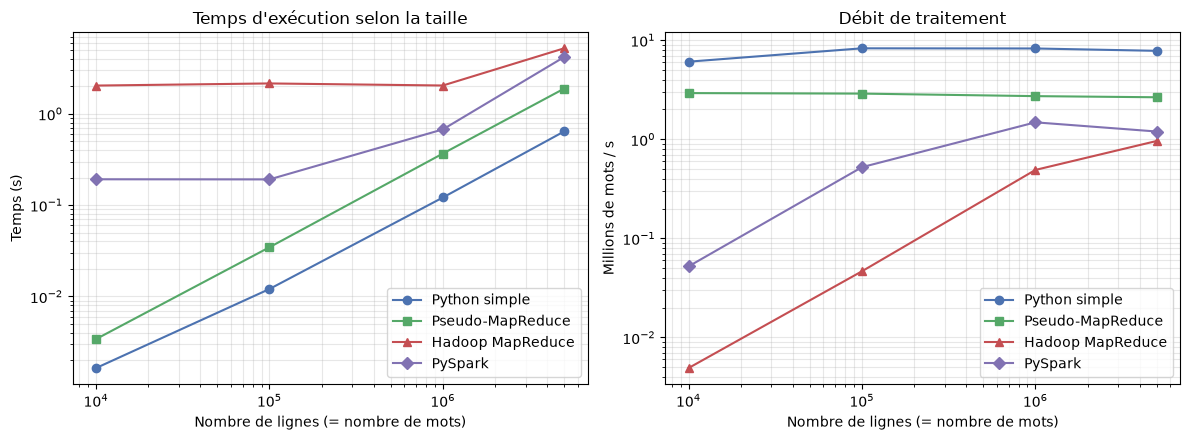

In [14]:
import matplotlib.pyplot as plt

methodes = [('Python simple (s)', 'Python simple', 'o', '#4C72B0'),
            ('Pseudo-MapReduce (s)', 'Pseudo-MapReduce', 's', '#55A868'),
            ('Hadoop job (s)', 'Hadoop MapReduce', '^', '#C44E52'),
            ('PySpark (s)', 'PySpark', 'D', '#8172B2')]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for col, nom, marqueur, couleur in methodes:
    if df[col].notna().any():
        ax1.plot(df['lignes'], df[col], marker=marqueur, color=couleur, label=nom)
        ax2.plot(df['lignes'], df['lignes'] / df[col] / 1e6, marker=marqueur, color=couleur, label=nom)

ax1.set(xscale='log', yscale='log', xlabel='Nombre de lignes (= nombre de mots)', ylabel='Temps (s)',
        title="Temps d'exécution selon la taille")
ax2.set(xscale='log', yscale='log', xlabel='Nombre de lignes (= nombre de mots)', ylabel='Millions de mots / s',
        title='Débit de traitement')
for ax in (ax1, ax2):
    ax.grid(True, which='both', alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

In [15]:
# Chiffres clés utilisés dans l'analyse
premier, dernier = df.iloc[0], df.iloc[-1]
print(f"Taille multipliée par {dernier['lignes'] / premier['lignes']:.0f}")
for col, nom in [('Python simple (s)', 'Python simple'), ('Pseudo-MapReduce (s)', 'Pseudo-MapReduce'),
                 ('Hadoop job (s)', 'Hadoop'), ('PySpark (s)', 'PySpark')]:
    if df[col].notna().all():
        print(f"  {nom:<17}: temps × {dernier[col] / premier[col]:.1f}")
print(f"Surcoût pseudo-MR : de {df['Surcoût pseudo-MR (×)'].min():.1f}× à {df['Surcoût pseudo-MR (×)'].max():.1f}×")
if df['PySpark (s)'].notna().all():
    plus_rapide = df.loc[df['PySpark (s)'] < df['Python simple (s)'], 'lignes']
    print('PySpark plus rapide que Python simple à partir de :',
          f"{plus_rapide.min():,} lignes" if len(plus_rapide) else 'jamais sur les tailles testées')

Taille multipliée par 500
  Python simple    : temps × 388.6
  Pseudo-MapReduce : temps × 550.9
  Hadoop           : temps × 2.6
  PySpark          : temps × 21.8
Surcoût pseudo-MR : de 2.1× à 3.0×
PySpark plus rapide que Python simple à partir de : jamais sur les tailles testées


## 8. Analyse

**Python simple vs pseudo-MapReduce.** Les deux temps croissent à peu près proportionnellement à la taille du fichier. La version pseudo-MapReduce reste plus lente d'un facteur de l'ordre de 2 à 3,5 (voir la colonne « Surcoût pseudo-MR ») : elle construit une liste de toutes les paires `(mot, 1)`, puis une liste de `1` par mot dans `shuffle`, avant de les additionner. Ce surcoût porte aussi sur la **mémoire** : toutes les paires intermédiaires sont stockées en même temps, ce qui devient le facteur limitant sur de gros fichiers.

**Hadoop : un coût fixe qui s'amortit.** Chaque job Hadoop paie un coût fixe de plusieurs secondes, quelle que soit la taille du fichier : démarrage de la JVM, chargement des bibliothèques Hadoop, préparation des tâches Map et Reduce, écriture du résultat. Sur les petits fichiers, ce coût écrase complètement le temps de calcul utile (le rapport mesurait 12 s contre 0,012 s en Python sur le petit fichier, soit un facteur d'environ 1000). Quand la taille augmente, le temps Hadoop croît **beaucoup plus lentement** que celui de Python, car la part du coût fixe diminue : le rapport Hadoop / Python baisse quand m augmente.

**PySpark : le meilleur des deux.** Une fois la session démarrée (quelques secondes, payées une seule fois), chaque comptage Spark ne coûte qu'un petit surcoût fixe de planification des tâches. Sur les petits fichiers, il reste plus lent que Python, mais beaucoup plus rapide que Hadoop, qui relance Java et écrit sur disque à chaque job. Quand la taille augmente, Spark répartit le travail sur tous les cœurs du processeur (`local[*]`) et garde les données intermédiaires en mémoire : son temps croît plus lentement que celui de Python, et il peut le rattraper sur les plus gros fichiers (voir la ligne « PySpark plus rapide que Python simple à partir de » ci-dessus). Le `reduceByKey` combine aussi les comptes localement avant le shuffle, ce qui évite de faire circuler une paire `(mot, 1)` par mot, contrairement à notre pseudo-MapReduce.

**Limites du mode local.** Ici, Hadoop tourne en mode local, dans un seul processus Java, sans HDFS ni YARN, et Spark n'utilise que les cœurs d'une seule machine. Il n'y a donc ni parallélisme sur plusieurs nœuds, ni gain de distribution : le point où Hadoop dépasse Python n'est pas atteint avec quelques dizaines de Mo. Son intérêt apparaît sur un vrai cluster, avec des données de l'ordre du Go ou plus, notamment **plus grandes que la RAM**, ce que les versions Python ne savent pas traiter. Les résultats dépendent aussi de la machine : les chiffres ci-dessus sont ceux de mon ordinateur.

## 9. Conclusion

| Critère | Python simple | Pseudo-MapReduce | Hadoop MapReduce | PySpark |
|---|---|---|---|---|
| Mise en œuvre | quelques lignes | quelques fonctions | installation et configuration lourdes | `pip install pyspark` + Java |
| Petits fichiers (Ko → quelques Mo) | **le plus rapide** | rapide, mais 2 à 3,5 fois plus lent | très lent (coût fixe de plusieurs secondes par job) | démarrage de quelques secondes, puis rapide |
| Fichiers moyens (dizaines à centaines de Mo) | rapide tant que la RAM suffit | plus lent et gourmand en mémoire | coût fixe amorti, mais pas de gain sur une seule machine | **utilise tous les cœurs**, calcul en mémoire |
| Très gros volumes (Go → To, > RAM) | impossible (tout en mémoire) | impossible (paires intermédiaires en mémoire) | **adapté** : blocs HDFS, parallélisme, tolérance aux pannes | **adapté** sur un cluster, et en général plus rapide que Hadoop |
| Intérêt pédagogique | référence | comprendre map / shuffle / reduce | MapReduce « historique » en production | MapReduce moderne, en mémoire, API concise |

Les quatre approches donnent exactement le même résultat. Elles forment une progression naturelle : la **simplicité** du traitement local, la **modularité** du modèle MapReduce simulé, la **puissance** du traitement distribué avec Hadoop, puis la **rapidité** de Spark, qui garde le modèle MapReduce mais travaille en mémoire. Pour de petits fichiers, Python reste le plus efficace ; les frameworks distribués ne deviennent intéressants que sur de gros volumes.

In [16]:
# Libère les ressources de Spark
if SPARK_DISPO:
    spark.stop()